# Quasi Monte Carlo
María Fernanda Gómez Flores  
Simulación de Procesos Financieros  
2 de noviembre de 2026

## Objetivo
En esta práctica comparo el método de Monte Carlo tradicional con Quasi Monte Carlo utilizando secuencias de Sobol. Monte Carlo trabaja con números pseudoaleatorios, mientras que Sobol genera puntos que buscan distribuirse de una manera más uniforme.

Primero reviso la distribución uniforme, después aproximo una integral y una probabilidad y, al final, simulo trayectorias del precio de una acción para calcular opciones call. La idea es observar cómo influye el método de generación de números en las estimaciones.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import qmc, norm

## 1. Distribución uniforme
Primero genero números aleatorios entre 0 y 1 para distintos tamaños de muestra: 50, 100, 500, 1,000 y 10,000 observaciones. La distribución uniforme asigna la misma densidad de probabilidad a todos los valores de este intervalo.

Con los histogramas puedo observar qué pasa al aumentar la cantidad de datos. En teoría, conforme la muestra se vuelve más grande, las frecuencias de los intervalos deberían ser relativamente más parecidas. Utilizo la semilla 32 para que la simulación sea reproducible.

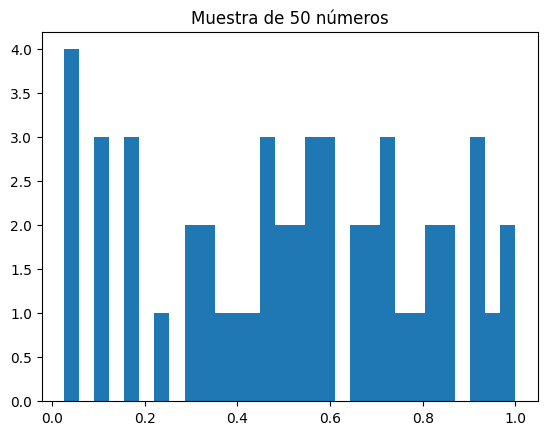

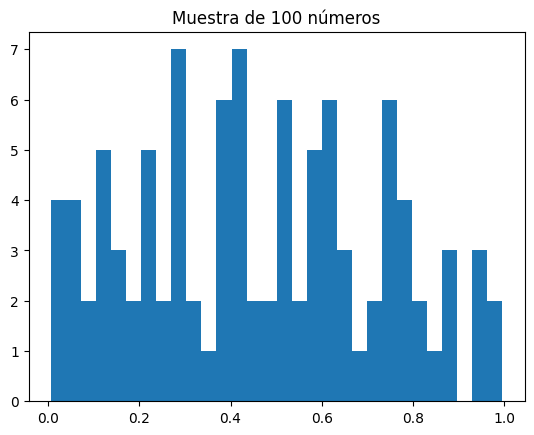

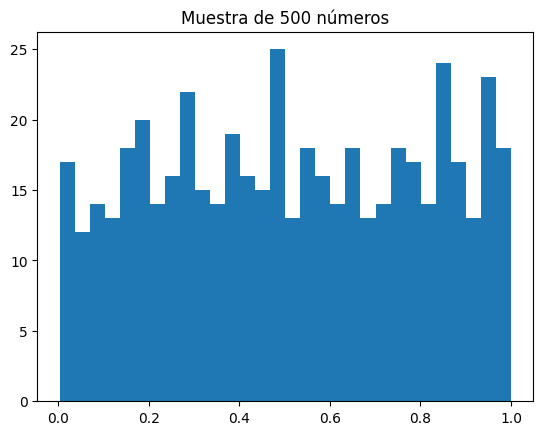

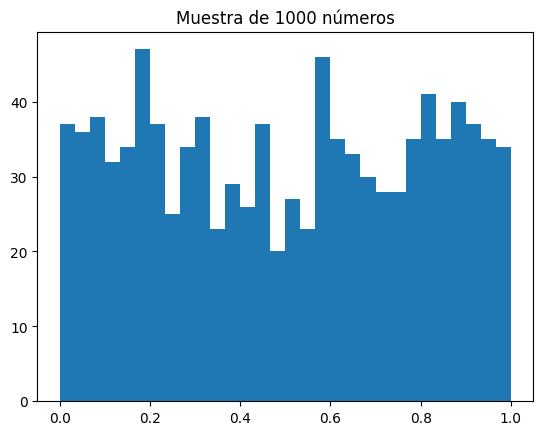

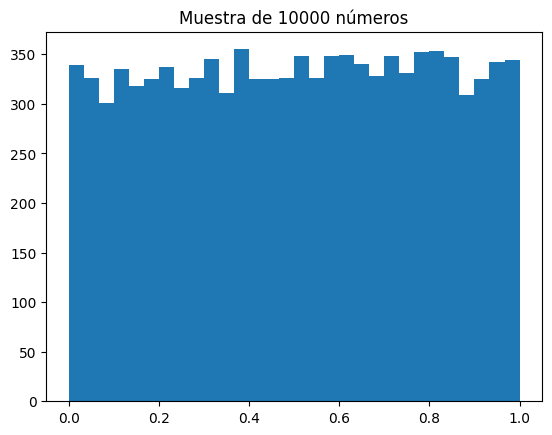

In [2]:
np.random.seed(32)
M = [50, 100, 500, 1000, 10000]

for i in M:
    numeros = np.random.uniform(0, 1, i)
    plt.hist(numeros, bins=30)
    plt.title(f"Muestra de {i} números")
    plt.show()

### Interpretación
Con pocas observaciones algunos intervalos tienen más datos que otros y el histograma se ve irregular. Cuando aumenta la muestra, las frecuencias tienden a equilibrarse y es más fácil reconocer la distribución uniforme.

Esto no significa que todos los intervalos tengan exactamente la misma frecuencia, sino que una muestra más grande permite observar mejor la distribución original. En este primer ejercicio todavía utilizo números pseudoaleatorios, no Sobol.

## 2. Integral con Monte Carlo y Sobol
Voy a aproximar la integral de la función cuadrática entre 0 y 1 mediante los dos métodos.

$$\int_0^1 x^2\,dx=\frac{1}{3}\approx 0.3333$$

Como el intervalo tiene longitud 1, puedo aproximar esta integral con el promedio de los valores de la función evaluados en los puntos generados:

$$\hat I=\frac{1}{M}\sum_{i=1}^{M}x_i^2$$

Con Monte Carlo genero valores uniformes de manera pseudoaleatoria; con Sobol genero puntos distribuidos más regularmente. Comparo 128, 256, 512, 1,024, 2,048 y 4,096 puntos. Utilizo potencias de 2 porque son adecuadas para la construcción de las secuencias de Sobol.

In [3]:
M = [128, 256, 512, 1024, 2048, 4096]
real = 1/3
integral_mc = []
integral_sobol = []

for i in M:
    np.random.seed(32)
    x = np.random.uniform(0, 1, i)
    integral_mc.append(np.mean(x**2))

    sobol = qmc.Sobol(d=1, scramble=True, seed=32)
    u = sobol.random_base2(m=int(np.log2(i)))
    integral_sobol.append(np.mean(u[:,0]**2))

print("Monte Carlo:", integral_mc)
print("Sobol:", integral_sobol)

Monte Carlo: [np.float64(0.30854711735747725), np.float64(0.32245371132258327), np.float64(0.3297339181071269), np.float64(0.33829276073226644), np.float64(0.33424652405930455), np.float64(0.33535130044269934)]
Sobol: [np.float64(0.33321900929634596), np.float64(0.3332190111589911), np.float64(0.3333334520769616), np.float64(0.33333345207696163), np.float64(0.33333345207696163), np.float64(0.33333345207696163)]


### 2.1 Comparación de errores
Como conozco el valor teórico de la integral, puedo medir qué tan cerca queda cada estimación utilizando el error absoluto.

$$\text{Error absoluto}=|\hat I-I|$$

En la tabla aparecen las estimaciones de Monte Carlo y Sobol, junto con sus errores. Después hago una gráfica para comparar la evolución del error conforme aumenta el número de simulaciones. Entre menor sea el error, más cercana estará la aproximación al valor real.

In [4]:
error_mc = []
error_sobol = []

for i in integral_mc:
    error_mc.append(abs(i-real))

for i in integral_sobol:
    error_sobol.append(abs(i-real))

comp = pd.DataFrame({"M": M, "Integral MC": integral_mc, "Integral Sobol": integral_sobol, "Error MC": error_mc, "Error Sobol": error_sobol})
comp

,M,Integral MC,Integral Sobol,Error MC,Error Sobol
0,128,0.308547,0.333219,0.024786,1.143240e-04
1,256,0.322454,0.333219,0.010880,1.143222e-04
2,512,0.329734,0.333333,0.003599,1.187436e-07
3,1024,0.338293,0.333333,0.004959,1.187436e-07
4,2048,0.334247,0.333333,0.000913,1.187436e-07
5,4096,0.335351,0.333333,0.002018,1.187436e-07


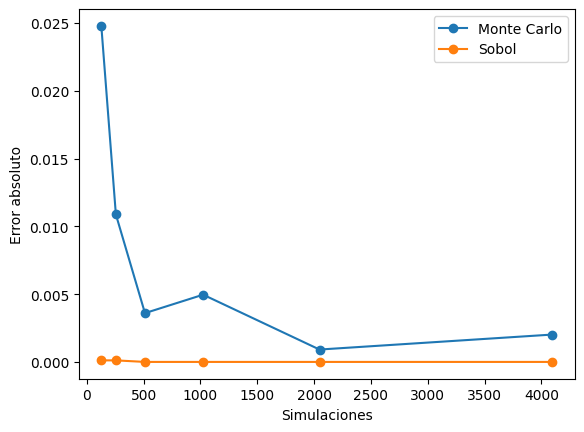

In [5]:
plt.plot(M, error_mc, marker="o", label="Monte Carlo")
plt.plot(M, error_sobol, marker="o", label="Sobol")
plt.xlabel("Simulaciones")
plt.ylabel("Error absoluto")
plt.legend()
plt.show()

### Interpretación de la integral
La tabla y la gráfica me permiten comparar directamente las aproximaciones con el valor exacto de 0.3333. Sobol busca cubrir el intervalo de manera más uniforme, por lo que puede disminuir el error en una función sencilla como esta.

Sin embargo, no necesariamente el error disminuye en cada incremento del tamaño de la muestra. Tampoco puedo concluir con una sola simulación que Sobol siempre será mejor: los resultados corresponden a estos tamaños de muestra y a la semilla utilizada.

## 3. Estimación de una probabilidad
Ahora quiero calcular la probabilidad de que una variable con distribución normal estándar sea mayor que 1.

$$P(Z>1)=1-\Phi(1)\approx 0.1587$$

Primero calculo la probabilidad teórica mediante la función de distribución acumulada de la normal. Para Monte Carlo genero números normales y cuento la proporción que supera 1.

En Sobol, primero genero números uniformes y después los transformo a una normal estándar utilizando la función de distribución inversa. Finalmente comparo las probabilidades estimadas y sus errores absolutos con el valor teórico.

In [6]:
prob_real = 1-norm.cdf(1)
prob_mc = []
prob_sobol = []

for i in M:
    np.random.seed(32)
    z = np.random.normal(0, 1, i)
    prob_mc.append(np.mean(z>1))

    sobol = qmc.Sobol(d=1, scramble=True, seed=32)
    u = sobol.random_base2(m=int(np.log2(i)))
    z_sobol = norm.ppf(np.clip(u[:,0], 1e-12, 1-1e-12))
    prob_sobol.append(np.mean(z_sobol>1))

probabilidades = pd.DataFrame({"M": M, "Prob MC": prob_mc, "Prob Sobol": prob_sobol, "Error MC": np.abs(np.array(prob_mc)-prob_real), "Error Sobol": np.abs(np.array(prob_sobol)-prob_real)})
print("Probabilidad teórica:", prob_real)
probabilidades

Probabilidad teórica: 0.15865525393145707


,M,Prob MC,Prob Sobol,Error MC,Error Sobol
0,128,0.187500,0.156250,0.028845,0.002405
1,256,0.203125,0.156250,0.044470,0.002405
2,512,0.177734,0.158203,0.019079,0.000452
3,1024,0.166992,0.158203,0.008337,0.000452
4,2048,0.149902,0.158691,0.008753,0.000036
5,4096,0.163330,0.158691,0.004675,0.000036


### Interpretación de la probabilidad
La estimación se obtiene dividiendo el número de valores que cumplen Z mayor que 1 entre el total de simulaciones. El resultado teórico es aproximadamente 15.87%, de modo que una estimación cercana a ese porcentaje tiene un error pequeño.

La tabla permite revisar cuál de los métodos se acerca más al valor teórico con cada tamaño de muestra. Como se trata de contar los valores que cumplen una condición, la estimación puede cambiar en saltos al agregar más observaciones.

## 4. Simulación de trayectorias con Sobol
En esta parte simulo el comportamiento del precio de una acción durante un año de 252 días de operación. Para representar sus cambios utilizo un movimiento browniano geométrico, que incorpora una tasa anual y la volatilidad.

$$S_{t+1}=S_t e^{(r-\frac{1}{2}\sigma^2)dt+\sigma\sqrt{dt}Z}$$

Donde:
- S0 = 100: precio inicial de la acción.
- K = 100: precio de ejercicio de las opciones.
- r = 0.05: tasa anual del modelo (5%).
- V = 0.20: volatilidad anual (20%).
- T = 1: periodo de un año.
- n = 252: número de días simulados.
- M = 1,024: número de trayectorias.
- dt = T/n: duración de cada paso.

Genero puntos de Sobol con 252 dimensiones, una por día, y los transformo a valores normales mediante la función inversa de la normal. Después calculo el precio del siguiente día a partir del precio anterior hasta completar cada trayectoria.

In [7]:
S0 = 100
K = 100
r = 0.05
V = 0.20
T = 1
n = 252
M = 1024
dt = T/n

In [8]:
# Números normales a partir de Sobol
sobol = qmc.Sobol(d=n, scramble=True, seed=32)
u = sobol.random_base2(m=10)
z = norm.ppf(np.clip(u, 1e-12, 1-1e-12))

precios = np.zeros((M, n+1))
precios[:,0] = S0

for i in range(n):
    precios[:,i+1] = precios[:,i]*np.exp((r-(1/2)*V**2)*dt + V*np.sqrt(dt)*z[:,i])

precios.shape

(1024, 253)

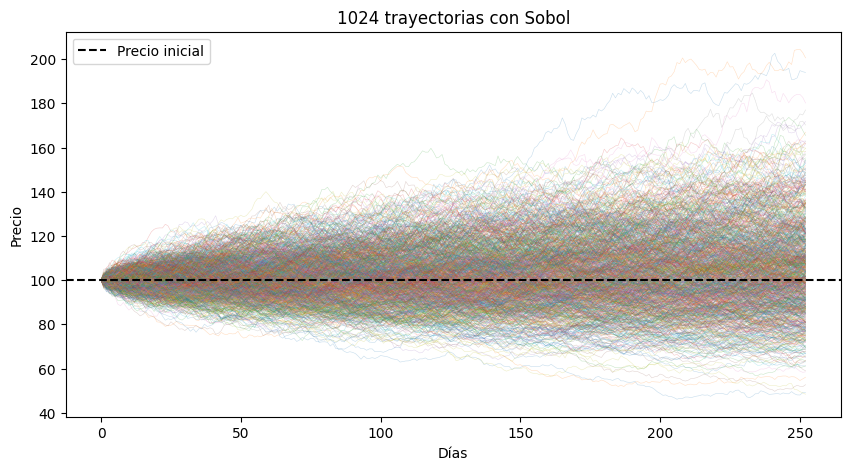

In [9]:
# Trayectorias de Sobol
plt.figure(figsize=(10,5))
for i in range(M):
    plt.plot(precios[i,:], linewidth=0.4, alpha=0.25)
plt.axhline(S0, linestyle="--", color="black", label="Precio inicial")
plt.xlabel("Días")
plt.ylabel("Precio")
plt.title("1024 trayectorias con Sobol")
plt.legend()
plt.show()

### 4.1 Trayectoria destacada
La primera gráfica presenta las 1,024 trayectorias simuladas, todas con precio inicial de 100. Para analizar con más detalle una de ellas, en la segunda gráfica destaco la trayectoria 0 y señalo:

- Precio final: el valor de la acción al terminar el año.
- Strike: el precio de ejercicio, que en este caso es 100.
- Precio promedio: la media de los precios observados a lo largo de la trayectoria.

Estos valores serán útiles para calcular las dos opciones: la europea utiliza el precio final y la asiática utiliza el promedio de la trayectoria.

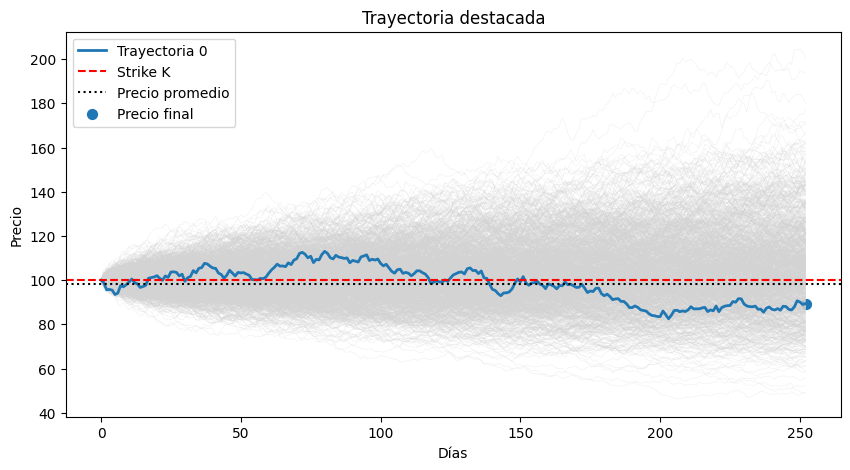

In [10]:
idx = 0
promedio = np.mean(precios[idx,:])

plt.figure(figsize=(10,5))
for i in range(M):
    plt.plot(precios[i,:], color="lightgray", linewidth=0.4, alpha=0.35)

plt.plot(precios[idx,:], linewidth=2, label="Trayectoria 0")
plt.axhline(K, color="red", linestyle="--", label="Strike K")
plt.axhline(promedio, color="black", linestyle=":", label="Precio promedio")
plt.scatter(n, precios[idx,-1], s=50, label="Precio final")
plt.xlabel("Días")
plt.ylabel("Precio")
plt.title("Trayectoria destacada")
plt.legend()
plt.show()

### Interpretación de las trayectorias
Aunque todas las trayectorias comienzan en 100, sus precios evolucionan de manera distinta por los valores normales que intervienen en cada día de la simulación.

La trayectoria destacada solo es un ejemplo para visualizar la diferencia entre el precio final y el promedio. No representa por sí sola el resultado total de las opciones. Para calcular sus pagos voy a utilizar todas las trayectorias simuladas.

### 4.2 Valuación de una call europea y una call asiática
Con los precios simulados calculo dos opciones de compra con K = 100.

La call europea depende del precio al vencimiento. Su pago es la diferencia positiva entre el precio final y el strike, o cero si la acción termina por debajo de este valor.

$$\text{Payoff europeo}=\max(S_T-K,0)$$

La call asiática depende del precio promedio de la acción a lo largo de cada trayectoria. En este notebook el promedio incluye también el precio inicial.

$$\text{Payoff asiático}=\max(\bar S-K,0)$$

Primero calculo el pago de cada trayectoria y después obtengo el payoff promedio de las 1,024 simulaciones. Este resultado corresponde al pago estimado al vencimiento.

Para calcular el precio presente de la opción descuento ese pago promedio con la tasa y el plazo del modelo:

$$C_0=e^{-rT}\times\text{Payoff promedio}$$

Así puedo comparar el pago al vencimiento con el precio estimado de la opción hoy.

In [11]:
# Call europea
call_europea = []
for i in precios[:,-1]:
    call_europea.append(max(i-K, 0))

# Call asiática
call_asiatica = []
for i in range(M):
    promedio = np.mean(precios[i,:])
    call_asiatica.append(max(promedio-K, 0))

# Pago promedio al vencimiento
pago_europea = np.mean(call_europea)
pago_asiatica = np.mean(call_asiatica)

# Valor presente
precio_europea = pago_europea * np.exp(-r*T)
precio_asiatica = pago_asiatica * np.exp(-r*T)

print("Pago promedio call europea:", round(pago_europea,4))
print("Pago promedio call asiática:", round(pago_asiatica,4))
print("Precio call europea:", round(precio_europea,4))
print("Precio call asiática:", round(precio_asiatica,4))

Pago promedio call europea: 11.0384
Pago promedio call asiática: 6.0386
Precio call europea: 10.5
Precio call asiática: 5.744


### 4.3 Comparación con Monte Carlo tradicional
Para hacer una comparación más completa, repito la simulación del precio de la acción pero utilizando números normales pseudoaleatorios. Mantengo los mismos parámetros: precio inicial, strike, tasa, volatilidad, plazo, número de días y 1,024 trayectorias.

Después calculo los pagos de la call europea y la asiática con Monte Carlo y los comparo con los obtenidos mediante Sobol. La tabla final presenta dos cantidades para cada método:

- Pago: promedio de los pagos estimados al vencimiento.
- Precio: valor presente obtenido al descontar ese pago.

Los resultados pueden cambiar porque cada método genera las simulaciones de manera diferente. Como aquí no calculo un valor teórico exacto para las opciones, la diferencia entre las estimaciones no demuestra por sí sola que un método sea más preciso que el otro.

In [12]:
np.random.seed(32)
z_mc = np.random.normal(0, 1, (M,n))
precios_mc = np.zeros((M,n+1))
precios_mc[:,0] = S0

for i in range(n):
    precios_mc[:,i+1] = precios_mc[:,i]*np.exp((r-(1/2)*V**2)*dt + V*np.sqrt(dt)*z_mc[:,i])

europea_mc = []
asiatica_mc = []

for i in range(M):
    europea_mc.append(max(precios_mc[i,-1]-K,0))
    promedio = np.mean(precios_mc[i,:])
    asiatica_mc.append(max(promedio-K,0))

comp_opciones = pd.DataFrame({
    "Opción": ["Europea", "Asiática"],
    "Pago MC": [np.mean(europea_mc), np.mean(asiatica_mc)],
    "Pago Sobol": [pago_europea, pago_asiatica],
    "Precio MC": [np.mean(europea_mc)*np.exp(-r*T), np.mean(asiatica_mc)*np.exp(-r*T)],
    "Precio Sobol": [precio_europea, precio_asiatica]
})
comp_opciones.round(4)

,Opción,Pago MC,Pago Sobol,Precio MC,Precio Sobol
0,Europea,11.6479,11.0384,11.0798,10.500
1,Asiática,6.1619,6.0386,5.8614,5.744


## Conclusión
Con esta práctica comparé Monte Carlo tradicional y Quasi Monte Carlo con Sobol utilizando problemas matemáticos y una aplicación financiera.

Primero observé que los histogramas de una distribución uniforme tienden a verse más equilibrados al aumentar el tamaño de la muestra. Después utilicé ambos métodos para estimar una integral y una probabilidad. Como conocía sus valores teóricos, pude calcular el error absoluto y analizar qué tan cerca estaba cada estimación del resultado esperado.

En la aplicación financiera simulé 1,024 trayectorias del precio de una acción durante 252 días mediante movimiento browniano geométrico. A partir de estos precios calculé una call europea utilizando el valor al vencimiento y una call asiática utilizando el promedio de cada trayectoria. También diferencié entre el pago promedio al vencimiento y el precio presente de las opciones.

Lo más importante que observé es que la forma de generar los números influye en el resultado de una simulación. Sobol distribuye los puntos de una manera más uniforme y puede ayudar a reducir el error en algunos ejercicios, pero esto no garantiza que siempre sea mejor. Por eso es importante comparar las estimaciones con valores teóricos cuando sea posible y analizar las diferencias antes de sacar conclusiones.